# Лабораторная работа №2
## Морфологический анализ, частеречная разметка (POS-tagging) и извлечение синтаксических структур

**Датасет:** Phishing Email Dataset (`datasets/phishing_email/`), **сырые** исходные файлы `CEAS_08`, `Enron`, `Ling`, `Nazario`, `Nigerian_Fraud`, `SpamAssasin` (поля `subject` + `body`, метка `label`: 1 — фишинг/спам, 0 — легитимное письмо).

**Почему не `phishing_email.csv`.** Сводный файл уже предобработан авторами: нижний регистр, нет пунктуации и стоп-слов (см. lab1). Для этой работы это критично. Без пунктуации нельзя разбить текст на предложения. Без служебных слов (`the`, `is`, `to`) парсер зависимостей строит бессмысленные деревья. Местоимения `he/she/it/they`, нужные для разрешения анафоры, удалены как стоп-слова. Поэтому вся работа выполнена на объединении сырых файлов.

**Инструменты:** spaCy 3.8 (`en_core_web_sm`) — POS-тэггер, морфология и парсер зависимостей; NLTK `names` и `wordnet` — словари имён и слов (для поиска ошибок тэггера и определения рода в анафоре).

In [1]:
import re
import html
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import spacy
from spacy import displacy
from spacy.language import Language
from IPython.display import display, HTML

ROOT = Path.cwd().parent if Path.cwd().name == "lab2" else Path.cwd()
DATA = ROOT / "datasets" / "phishing_email"
FIG = ROOT / "lab2" / "figures"
FIG.mkdir(exist_ok=True)

NLTK_DIR = ROOT / ".venv" / "nltk_data"
nltk.data.path.insert(0, str(NLTK_DIR))
for res, pkg in [("corpora/names", "names"), ("corpora/wordnet", "wordnet")]:
    try:
        nltk.data.find(res)
    except LookupError:
        nltk.download(pkg, download_dir=str(NLTK_DIR), quiet=True)
from nltk.corpus import names as nltk_names, wordnet as wn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Цвета классов — как в lab1: легитимные — синий, фишинг — оранжевый
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}
CLASS_NAMES = {0: "легитимные (0)", 1: "фишинг (1)"}
PALETTE = {CLASS_NAMES[k]: v for k, v in CLASS_COLORS.items()}
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#c3c2b7", "grid.color": "#e6e5df"})
pd.set_option("display.max_colwidth", 160)
print("spaCy", spacy.__version__)

spaCy 3.8.18


## 0. Данные: сырой корпус, щадящая очистка, подвыборка

Объединяем шесть исходных файлов (как в lab1) и удаляем точные дубликаты.

In [2]:
parts = []
for fn in sorted(DATA.glob("*.csv")):
    if fn.name == "phishing_email.csv":
        continue
    part = pd.read_csv(fn)
    part["source"] = fn.stem
    parts.append(part[["subject", "body", "label", "source"]])
raw = pd.concat(parts, ignore_index=True)
raw["text"] = raw["subject"].fillna("").astype(str) + "\n" + raw["body"].fillna("").astype(str)
raw = raw.drop_duplicates("text").reset_index(drop=True)
print("Сырой корпус:", raw.shape)
pd.crosstab(raw["source"], raw["label"], margins=True).rename(columns=CLASS_NAMES)

Сырой корпус: (82486, 5)


label,легитимные (0),фишинг (1),All
source,,,
CEAS_08,17312,21842,39154
Enron,15791,13976,29767
Ling,2401,458,2859
Nazario,0,1565,1565
Nigerian_Fraud,0,3332,3332
SpamAssasin,4091,1718,5809
All,39595,42891,82486


Очистка здесь **принципиально другая**, чем в lab1. Там текст готовился для n-граммной модели: нижний регистр, удаление пунктуации. Здесь текст идёт в POS-тэггер и парсер, которым **нужны** регистр, пунктуация и служебные слова. Поэтому убираем только то, что ломает токенизацию и не является языком:

* артефакты почтового формата: quoted-printable (`=3D`), HTML-теги и сущности, маркеры цитирования `>` в начале строк;
* URL и e-mail заменяем словами-плейсхолдерами `URL` / `EMAIL` (не `[URL]`, чтобы токенизатор не дробил скобки); для тэггера это просто существительное;
* линии-разделители (`-----`, `=====`) и не-ASCII символы;
* «разреженную» пунктуацию Enron/Ling (`it ' s`, `word .`) склеиваем обратно (`it's`, `word.`), иначе тэггер видит отдельные `'` и `s`;
* схлопываем пробелы. Переносы строк сохраняем: ниже они станут границами предложений. Исключение — «жёсткие» переносы посреди предложения: почтовые клиенты переносят текст по ~72 символа. Если строка длинная и не кончается точкой, а следующая начинается со строчной буквы, или строка оборвана на служебном слове (`the`, `of`, `your`…), склеиваем её со следующей. Без этого правила spaCy отрывал артикль от существительного и размечал «висящий» `the` как местоимение (тысячи случаев на подвыборке).

Длинные письма обрезаем до 2000 символов по границе слова. Для синтаксиса и POS-распределения начала письма достаточно, а время парсинга растёт линейно.

In [3]:
CLEANING_RULES = [
    ("qp_softbreak", re.compile(r"=\r?\n"), ""),
    ("qp_code",      re.compile(r"=[0-9A-F]{2}"), " "),
    ("html_block",   re.compile(r"<(script|style)\b.*?</\1\s*>", re.S | re.I), " "),
    ("html_tag",     re.compile(r"</?[a-zA-Z][a-zA-Z0-9]*(?:\s[^<>]{0,500})?/?>"), " "),
    ("html_entity",  re.compile(r"&(?:#\d{1,6}|#x[0-9a-fA-F]{1,6}|[a-zA-Z]{2,8});"),
                     lambda m: html.unescape(m.group(0))),
    ("quote_marker", re.compile(r"^[ \t]*(?:>[ \t]?)+", re.M), ""),
    ("url",          re.compile(r"(?:https?|ftp)://\S+|\bwww\.\S+", re.I), " URL "),
    ("url_spaced",   re.compile(r"\b(?:https?\s?:\s?/\s?/\s?|www\s\.\s)(?:[\w\-]+\s?\.\s?)*[a-z]{2,4}\b"
                                r"(?:\s?/\s?[\w\-.~%?=&]+)*", re.I), " URL "),
    ("email",        re.compile(r"[\w.+\-]+@[\w\-]+(?:\.[\w\-]+)+"), " EMAIL "),
    ("email_spaced", re.compile(r"[\w.\-]+\s@\s[\w\-]+(?:\s\.\s[\w\-]+)+"), " EMAIL "),
    ("separators",   re.compile(r"([=\-_*#~+.!?<>|/])(?:\s?\1){3,}"), " "),
    ("non_ascii",    re.compile(r"[^\x00-\x7f]+"), " "),
    # «разреженная» пунктуация Enron/Ling: "it ' s" -> "it's", "word ." -> "word."
    ("spaced_clitic", re.compile(r"(\w) ' (s|t|re|ve|ll|d|m)\b", re.I), r"\1'\2"),
    ("spaced_punct",  re.compile(r"(?<=\w) ([.,!?;:%)])(?=\s|$)"), r"\1"),
    ("spaced_paren",  re.compile(r"\( (?=\w)"), "("),
    ("hspace",        re.compile(r"[ \t\r\f\v]+"), " "),
    ("newlines",      re.compile(r"\s*\n\s*(?:\n\s*)*"), "\n"),
    # «жёсткие» переносы строк (~72 символа) посреди предложения: склеиваем, иначе перенос станет границей
    # предложения и разорвёт именную группу ("click on the\nlink" -> 'the' без существительного)
    ("unwrap_func",   re.compile(r"\b(the|a|an|of|to|in|on|at|for|from|with|by|and|or|your|our|my|is|are|be|will)\n", re.I),
                      r"\1 "),
    ("unwrap_long",   re.compile(r"(?<=[^\n]{40})(?<![.!?:;])\n(?=[a-z(])"), " "),
]
MAX_CHARS = 2000


def clean_text(text):
    for _, pattern, repl in CLEANING_RULES:
        text = pattern.sub(repl, text)
    text = text.strip()
    if len(text) > MAX_CHARS:
        cut = text.rfind(" ", 0, MAX_CHARS)
        text = text[:cut if cut > 0 else MAX_CHARS]
    return text


t0 = time.time()
raw["clean"] = [clean_text(t) for t in raw["text"]]
print(f"Очистка: {time.time() - t0:.0f} c")
raw = raw[raw["clean"].str.split().str.len() >= 5].drop_duplicates("clean").reset_index(drop=True)
print("После удаления коротких (<5 слов) и дубликатов после очистки:", raw.shape)

for src in ["Enron", "Nazario"]:
    row = raw[raw["source"] == src].iloc[3]
    print(f"\n===== {src}, label={row['label']} — ДО:\n{row['text'][:300]!r}\n----- ПОСЛЕ:\n{row['clean'][:300]!r}")

Очистка: 44 c


После удаления коротких (<5 слов) и дубликатов после очистки: (76351, 6)

===== Enron, label=0 — ДО:
'hpl nom for may 30 , 2001\n( see attached file : hplno 530 . xls )\r\n- hplno 530 . xls'
----- ПОСЛЕ:
'hpl nom for may 30, 2001\n(see attached file: hplno 530. xls)\n- hplno 530. xls'

===== Nazario, label=1 — ДО:
'IT-Service Help Desk\nPassword will expire in 3 days. Click Here To Validate E-mail Thank you, IT-Service Help Desk'
----- ПОСЛЕ:
'IT-Service Help Desk\nPassword will expire in 3 days. Click Here To Validate E-mail Thank you, IT-Service Help Desk'


**Подвыборка.** spaCy разбирает ~80 писем в секунду, поэтому весь корпус (~76 тыс. писем) парсился бы ~15 минут. Берём стратифицированную подвыборку: 4000 фишинговых и 4000 легитимных писем. Внутри класса доли источников сохраняются.

**Особенность данных:** Enron и Ling целиком в **нижнем регистре**, в отличие от остальных источников. Регистр сильно влияет на тэггер: без заглавной буквы имя собственное не опознаётся как PROPN (см. п. 2, ошибки тэггера).

In [4]:
N_PER_CLASS = 4000
sample = (raw.groupby("label", group_keys=False)
             .sample(N_PER_CLASS, random_state=SEED)
             .sample(frac=1, random_state=SEED)      # перемешиваем, чтобы классы не шли блоками
             .reset_index(drop=True))
pd.crosstab(sample["source"], sample["label"], margins=True).rename(columns=CLASS_NAMES)

label,легитимные (0),фишинг (1),All
source,,,
CEAS_08,1745,1808,3553
Enron,1574,1471,3045
Ling,246,46,292
Nazario,0,156,156
Nigerian_Fraud,0,333,333
SpamAssasin,435,186,621
All,4000,4000,8000


**Парсинг.** К стандартному конвейеру spaCy (`tok2vec → tagger → parser → attribute_ruler → lemmatizer → ner`) добавляем свой компонент перед парсером. Он ставит границу предложения после каждого перевода строки. В письмах строка — это почти всегда отдельная единица: тема, приветствие, подпись, пункт списка. Без этого парсер склеивает `Dear Customer` со следующей строкой в одно «предложение».

In [5]:
@Language.component("newline_sentences")
def newline_sentences(doc):
    for i, tok in enumerate(doc[:-1]):
        if tok.is_space and "\n" in tok.text:
            doc[i + 1].is_sent_start = True
    return doc


nlp = spacy.load("en_core_web_sm")
nlp.add_pipe("newline_sentences", before="parser")
print(nlp.pipe_names)

t0 = time.time()
docs = list(nlp.pipe(sample["clean"], batch_size=64))
doc_tokens = [[t for t in d if not t.is_space] for d in docs]
n_sents = sum(1 for d in docs for _ in d.sents)
print(f"Разобрано {len(docs)} писем за {time.time() - t0:.0f} c: "
      f"{sum(map(len, doc_tokens)):,} токенов, {n_sents:,} предложений")

['tok2vec', 'tagger', 'newline_sentences', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


Разобрано 8000 писем за 102 c: 1,463,914 токенов, 135,505 предложений


## 1. Частеречная разметка (POS-tagging)

spaCy даёт для каждого токена универсальную часть речи (`pos_`, набор Universal Dependencies, 17 тегов), детальный тег Penn Treebank (`tag_`), морфологические признаки (`morph`: число, лицо, время, род местоимений…) и лемму. Пример разметки фишингового письма:

In [6]:
def token_table(span):
    return pd.DataFrame([{"token": t.text, "lemma": t.lemma_, "POS": t.pos_, "tag": t.tag_,
                          "morph": str(t.morph), "dep": t.dep_, "head": t.head.text}
                         for t in span if not t.is_space])


demo_doc = nlp("Dear Customer, we have detected unusual activity on your account. "
               "Please verify your identity by clicking the link below within 24 hours.")
token_table(demo_doc)

,token,lemma,POS,tag,morph,dep,head
0,Dear,Dear,PROPN,NNP,Number=Sing,compound,Customer
1,Customer,Customer,PROPN,NNP,Number=Sing,npadvmod,detected
2,",",",",PUNCT,",",PunctType=Comm,punct,detected
3,we,we,PRON,PRP,Case=Nom|Number=Plur|Person=1|PronType=Prs,nsubj,detected
4,have,have,AUX,VBP,Mood=Ind|Tense=Pres|VerbForm=Fin,aux,detected
5,detected,detect,VERB,VBN,Aspect=Perf|Tense=Past|VerbForm=Part,ROOT,detected
6,unusual,unusual,ADJ,JJ,Degree=Pos,amod,activity
7,activity,activity,NOUN,NN,Number=Sing,dobj,detected
8,on,on,ADP,IN,,prep,detected
9,your,your,PRON,PRP$,Person=2|Poss=Yes|PronType=Prs,poss,account


## 2. Распределение частей речи
### 2.1. Весь корпус

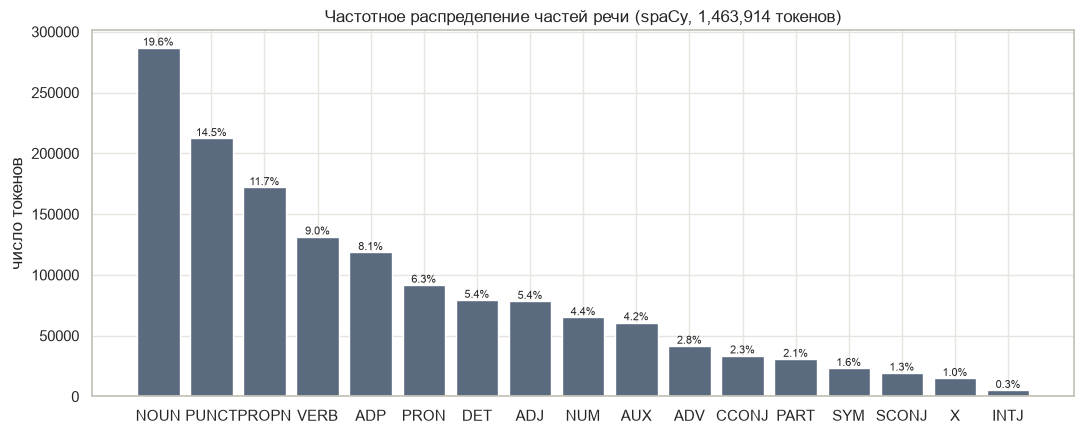

In [7]:
pos_counter = Counter(t.pos_ for toks in doc_tokens for t in toks)
pos_freq = pd.Series(pos_counter).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(pos_freq.index, pos_freq.values, color="#5b6b7f")
for i, (p, v) in enumerate(pos_freq.items()):
    ax.text(i, v, f"{v / pos_freq.sum():.1%}", ha="center", va="bottom", fontsize=8)
ax.set_title(f"Частотное распределение частей речи (spaCy, {pos_freq.sum():,} токенов)")
ax.set_ylabel("число токенов")
plt.tight_layout()
plt.savefig(FIG / "pos_corpus.png", dpi=120)
plt.show()

### 2.2. Фишинг vs легитимные письма

Длина писем в классах разная (фишинг короче, см. lab1). Поэтому сравниваем не абсолютные частоты, а **долю** каждой части речи внутри письма и усредняем по письмам.

In [8]:
POS_LIST = list(pos_freq.index)
rows = []
for toks, label in zip(doc_tokens, sample["label"]):
    c = Counter(t.pos_ for t in toks)
    rows.append({**{p: c[p] / len(toks) for p in POS_LIST}, "label": label})
pos_doc = pd.DataFrame(rows)

pos_cmp = pos_doc.groupby("label")[POS_LIST].mean().T.rename(columns=CLASS_NAMES)
pos_cmp["фишинг/легит"] = pos_cmp[CLASS_NAMES[1]] / pos_cmp[CLASS_NAMES[0]]
pos_cmp.style.format({CLASS_NAMES[0]: "{:.2%}", CLASS_NAMES[1]: "{:.2%}", "фишинг/легит": "{:.2f}"}) \
    .background_gradient(subset=["фишинг/легит"], cmap="RdBu_r", vmin=0.4, vmax=1.6)

label,легитимные (0),фишинг (1),фишинг/легит
NOUN,19.14%,21.74%,1.14
PUNCT,15.89%,12.19%,0.77
PROPN,11.59%,13.33%,1.15
VERB,8.93%,9.69%,1.08
ADP,7.78%,7.55%,0.97
PRON,5.64%,7.03%,1.25
DET,5.35%,4.38%,0.82
ADJ,4.65%,6.98%,1.50
NUM,5.13%,3.39%,0.66
AUX,4.32%,3.37%,0.78


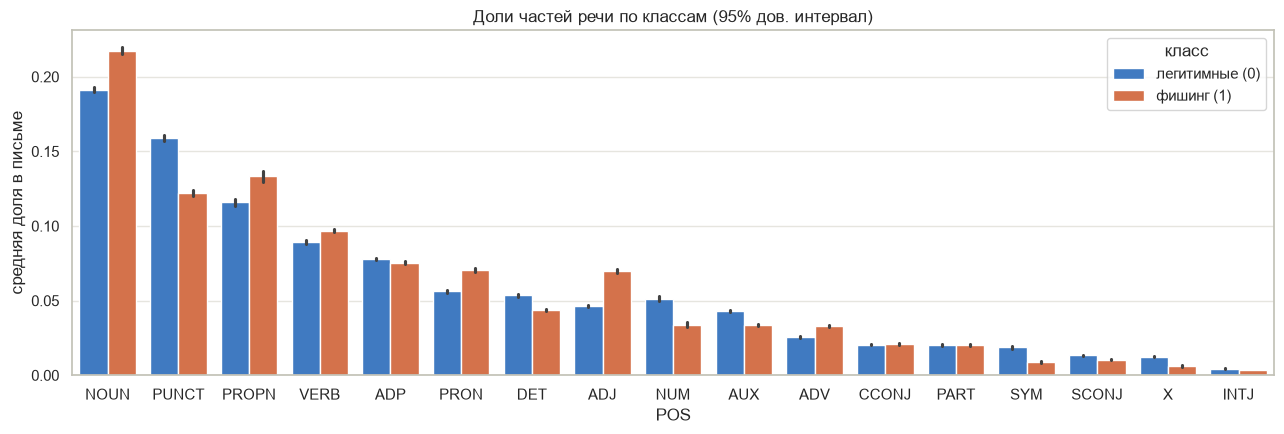

In [9]:
long = pos_doc.melt(id_vars=["label"], value_vars=POS_LIST, var_name="POS", value_name="share")
long["класс"] = long["label"].map(CLASS_NAMES)
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.barplot(data=long, x="POS", y="share", hue="класс", palette=PALETTE, errorbar=("ci", 95), ax=ax)
ax.set_ylabel("средняя доля в письме")
ax.set_title("Доли частей речи по классам (95% дов. интервал)")
plt.tight_layout()
plt.savefig(FIG / "pos_by_class.png", dpi=120)
plt.show()

### 2.3. Ошибки тэггера на шумных данных

Ручной разметки (золотого стандарта) у датасета нет. Поэтому кандидатов в ошибки ищем по **типовым ловушкам** почтового домена: капс, нижний регистр Enron, обфускация спам-слов, этикетные формулы, технический мусор. Каждую категорию затем проверяем глазами. Для каждой показываем самые частые случаи и случайные примеры с контекстом.

In [10]:
def context(tok, w=6):
    toks = [t.text for t in tok.doc[max(0, tok.i - w): tok.i + w + 1] if not t.is_space]
    return " ".join(toks)


def find_examples(pred, k=5, seed=SEED):
    """Все токены корпуса, удовлетворяющие pred(doc_idx, token) -> таблица частот и случайные примеры."""
    hits = [(di, t) for di, toks in enumerate(doc_tokens) for t in toks if pred(di, t)]
    freq = Counter((t.lower_, t.pos_) for _, t in hits)
    rnd = random.Random(seed)
    ex = rnd.sample(hits, min(k, len(hits)))
    print(f"Найдено токенов: {len(hits)}")
    display(pd.DataFrame([(w, p, n) for (w, p), n in freq.most_common(8)], columns=["слово", "spaCy", "раз"]).T)
    display(pd.DataFrame([{"токен": t.text, "spaCy": t.pos_, "источник": sample["source"][di],
                           "label": sample["label"][di], "контекст": context(t)} for di, t in ex]))
    return hits


_wn_cache = {}
def in_wordnet(w):
    if w not in _wn_cache:
        _wn_cache[w] = bool(wn.synsets(w))
    return _wn_cache[w]


MALE_NAMES = {n.lower() for n in nltk_names.words("male.txt")}
FEMALE_NAMES = {n.lower() for n in nltk_names.words("female.txt")}
ALL_NAMES = MALE_NAMES | FEMALE_NAMES

**Категория 1. Заголовки и выкрики КАПСОМ → PROPN.** Обычные словарные слова, написанные заглавными (рассылки CNN в CEAS_08, нигерийские письма), тэггер принимает за имена собственные:

In [11]:
hits_caps = find_examples(lambda di, t: t.is_upper and len(t) > 3 and t.pos_ == "PROPN" and t.text not in ("URL", "EMAIL")
                          and t.lower_ not in ALL_NAMES and in_wordnet(t.lower_)
                          and t.ent_type_ not in ("PERSON", "GPE", "ORG"), k=6)

Найдено токенов: 4009


,0,1,2,3,4,5,6,7
слово,story,full,begin,signature,signed,bank,urgent,dear
spaCy,PROPN,PROPN,PROPN,PROPN,PROPN,PROPN,PROPN,PROPN
раз,159,141,141,85,72,55,46,41


,токен,spaCy,источник,label,контекст
0,RESPONSE,PROPN,Nigerian_Fraud,1,"URGENT RESPONSE NEEDED DEAR FRIEND ,"
1,ADVISE,PROPN,CEAS_08,0,YOU THAT ANY U.S. FEDERAL TAX ADVISE INCLUDED IN THIS COMMUNICATION IS NOT
2,PREFIX,PROPN,SpamAssasin,0,""" > "" NUMBER=3 PREFIX = repeat $ STRING $ NUMBER"
3,STORY,PROPN,CEAS_08,1,Aug 2008 10:42:42 +0100 FULL STORY You have agreed to receive
4,HORRIBLE,PROPN,CEAS_08,0,know better ) a totally HORRIBLE impression of both Suse and Linux
5,SELECT,PROPN,CEAS_08,0,sql_verbose : yes so the SELECT call is supposed to append @domain


**Категория 2. Нижний регистр Enron/Ling: имена и названия → NOUN.** Обратная ситуация: в Enron и Ling всё написано строчными, и имена людей (`vince`, `louise`) и компаний (`enron`) теряют главный признак имени собственного:

In [12]:
NAME_LIKE = {w for w in ALL_NAMES if not in_wordnet(w)}   # имена, не совпадающие с обычными словами
hits_lower = find_examples(lambda di, t: sample["source"][di] in ("Enron", "Ling")
                           and (t.lower_ in NAME_LIKE or t.lower_ == "enron")
                           and t.pos_ not in ("PROPN", "ADV", "ADP", "DET", "PRON"), k=6)

Найдено токенов: 3873


,0,1,2,3,4,5,6,7
слово,enron,vince,lon,louise,daren,wes,steve,shirley
spaCy,NOUN,NOUN,NOUN,NOUN,NOUN,NOUN,NOUN,NOUN
раз,1298,489,117,82,48,37,24,23


,токен,spaCy,источник,label,контекст
0,louise,NOUN,Enron,0,"fuel cell overview louise , attached below please find"
1,enron,NOUN,Enron,0,contract and facility requests for the enron companies listed below should be directed
2,andreas,NOUN,Enron,0,"re : garp 2001 convention andreas , am i entitled to"
3,vince,NOUN,Enron,0,the confusion ! carol vince j kaminski 10 / 12
4,vince,NOUN,Enron,0,scott - could you give vince a call or an email to
5,pam,NOUN,Enron,0,"0500 , you wrote : pam , please , let me"


**Категория 3. Обфускация спам-слов.** Спамеры портят написание, чтобы обойти фильтры: `vlagra`, `ciick`, `piease`, `aiso`. Для тэггера это неизвестные слова (OOV), и тег выбирается почти случайно по форме и контексту:

In [13]:
OBFUSCATED = {"ciick", "piease", "aiso", "miilion", "vlagra", "viiagra", "ciaalis", "viiicodin", "clalis", "vallum", "prlce", "wiil"}
hits_obf = find_examples(lambda di, t: t.lower_ in OBFUSCATED, k=8)

Найдено токенов: 95


,0,1,2,3,4,5,6,7
слово,wiil,vlagra,ciick,miilion,clalis,aiso,aiso,prlce
spaCy,NOUN,PROPN,NOUN,NOUN,PROPN,NOUN,VERB,NOUN
раз,29,11,11,9,5,5,4,3


,токен,spaCy,источник,label,контекст
0,clalis,PROPN,Enron,1,"our price $ 2 . 99 clalis , retail price $ 17 ."
1,vallum,NOUN,Enron,1,vlagra from $ 69 vallum from $ 70 amblen from
2,ciick,NOUN,Enron,1,super low prlce = = = ciick here to check out = =
3,vlagra,PROPN,Enron,1,"per 20 mg pill ! vlagra soft , 3 . 24 per"
4,wiil,VERB,Enron,1,- strongbuy how much it wiil up again ? the value
5,aiso,NOUN,Enron,1,"enhanced eiectronic shape recognition , wiil aiso generate substantial interest from the aforementioned"
6,miilion,NOUN,Enron,1,and cost upwards of $ 120 miilion in development expenditures . once completed
7,wiil,NOUN,Enron,1,professionai website . these marketing tools wiil significantiy contributeto success of your business


**Категория 4. Этикетные формулы писем.** Приветствия и прощания в начале строки (`Dear Sir`, `Hi John`, `Regards`) тэггер видит без глагола и с заглавной буквы и размечает как имя собственное. По UD `dear` здесь — ADJ, `hi`/`hello` — INTJ, `regards` — NOUN.

In [14]:
FORMULA_GOLD = {"dear": "ADJ", "hi": "INTJ", "hello": "INTJ", "regards": "NOUN", "sincerely": "ADV", "cheers": "INTJ",
                "thanks": "NOUN", "kindly": "ADV"}
formula_stats = Counter((t.lower_, t.pos_) for toks in doc_tokens for t in toks if t.lower_ in FORMULA_GOLD)
formula_df = (pd.DataFrame([(w, p, n) for (w, p), n in formula_stats.items()], columns=["слово", "POS", "n"])
              .pivot_table(index="слово", columns="POS", values="n", fill_value=0))
gold = formula_df.index.map(FORMULA_GOLD)
formula_df["доля ошибок"] = [1 - formula_df.loc[w].get(g, 0) / formula_df.loc[w].sum() for w, g in zip(formula_df.index, gold)]
formula_df.insert(0, "правильно (UD)", gold)
display(formula_df.style.format({"доля ошибок": "{:.0%}"}))
hits_formula = find_examples(lambda di, t: t.lower_ in FORMULA_GOLD and t.pos_ != FORMULA_GOLD[t.lower_]
                             and t.pos_ in ("PROPN", "VERB"), k=6)

POS,правильно (UD),ADJ,ADP,ADV,INTJ,NOUN,PROPN,VERB,X,доля ошибок
слово,,,,,,,,,,
cheers,INTJ,0.000000,0.000000,0.000000,0.000000,127.000000,19.000000,0.000000,0.000000,100%
dear,ADJ,325.000000,0.000000,0.000000,0.000000,19.000000,376.000000,0.000000,0.000000,55%
hello,INTJ,0.000000,0.000000,0.000000,215.000000,5.000000,97.000000,0.000000,0.000000,32%
hi,INTJ,32.000000,2.000000,1.000000,247.000000,18.000000,172.000000,1.000000,0.000000,48%
kindly,ADV,0.000000,0.000000,96.000000,0.000000,1.000000,9.000000,0.000000,0.000000,9%
regards,NOUN,0.000000,0.000000,0.000000,0.000000,332.000000,144.000000,50.000000,0.000000,37%
sincerely,ADV,0.000000,0.000000,165.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1%
thanks,NOUN,0.000000,0.000000,0.000000,1.000000,1150.000000,10.000000,1.000000,1.000000,1%


Найдено токенов: 879


,0,1,2,3,4,5,6,7
слово,dear,hi,regards,hello,regards,cheers,thanks,kindly
spaCy,PROPN,PROPN,PROPN,PROPN,VERB,PROPN,PROPN,PROPN
раз,376,172,144,97,50,19,10,9


,токен,spaCy,источник,label,контекст
0,Regards,PROPN,CEAS_08,0,beagle useful or not ? Regards . Say you go to
1,Dear,PROPN,SpamAssasin,1,"| | * * Dear Homeowner , * * *"
2,Hi,PROPN,SpamAssasin,1,"Hold'em , Omaha Omaha Hi / Lo 7 Card Stud"
3,Regards,PROPN,Nigerian_Fraud,1,"can handle it . Best Regards , Mr Nelson Brown ."
4,Hello,PROPN,Nazario,1,"Confirm your email Dear Customer , Hello PayPal Customer , We are sorry"
5,Thanks,PROPN,SpamAssasin,0,Re : Xine Dependencies Thanks Matthias ... After installing those packages


**Категория 5. Технический шум: имена файлов, плейсхолдеры.** Расширения файлов (`.txt`) в отчётах Enron размечаются как обычные слова. Сюда же относятся наши плейсхолдеры `URL`/`EMAIL`. Тэггер неустойчив даже на них: одно и то же «слово» в зависимости от контекста получает NOUN, PROPN или VERB.

In [15]:
display(pd.DataFrame(Counter((t.text, t.pos_) for toks in doc_tokens for t in toks if t.text in ("URL", "EMAIL")).most_common(8),
                     columns=["плейсхолдер/POS", "раз"]))
hits_tech = find_examples(lambda di, t: t.lower_ in ("txt", "xls", "doc", "pdf", "exe", "zip", "html", "py") and t.i > 0
                          and t.nbor(-1).text == "." and t.pos_ not in ("NOUN", "PROPN"), k=6)

,плейсхолдер/POS,раз
0,"(URL, NOUN)",3324
1,"(URL, PROPN)",2905
2,"(EMAIL, NOUN)",2699
3,"(EMAIL, PROPN)",848
4,"(URL, VERB)",5
5,"(EMAIL, ADV)",4
6,"(EMAIL, X)",3
7,"(EMAIL, PRON)",2


Найдено токенов: 56


,0
слово,txt
spaCy,VERB
раз,56


,токен,spaCy,источник,label,контекст
0,txt,VERB,Enron,0,iso final schedules \\ 2002012520 . txt
1,txt,VERB,Enron,0,iso final schedules \\ 2002010305 . txt load schedule $ $ $
2,txt,VERB,Enron,0,iso final schedules \\ 2002012803 . txt # # # can not
3,txt,VERB,Enron,0,iso final schedules \\ 2001122704 . txt
4,txt,VERB,Enron,0,iso final schedules \\ 2002020102 . txt
5,txt,VERB,Enron,0,iso final schedules \\ 2001121113 . txt load schedule $ $ $


### Разбор ошибок тэггера

Правильный тег указан по стандарту UD, на котором обучен `en_core_web_sm`.

| № | фрагмент из корпуса | токен | spaCy | верно | причина |
|---|---|---|---|---|---|
| 1 | `URGENT RESPONSE NEEDED DEAR FRIEND` (Nigerian_Fraud) | RESPONSE, DEAR | PROPN, PROPN | NOUN, ADJ | **Капс.** Модель опирается на форму слова (`XXXX`), а заглавными в обучающих данных пишутся аббревиатуры и названия. Так ошибочно размечено ≈4 тыс. словарных слов: `STORY`, `FULL`, `URGENT`, `BANK`… |
| 2 | `contract and facility requests for the enron companies` (Enron) | enron, vince, louise | NOUN | PROPN | **Нижний регистр.** Обратный эффект: без заглавной буквы имя не опознаётся. `enron` размечен как NOUN 1 298 раз, `vince` — 489 раз. |
| 3 | `wiil aiso generate substantial interest`, `vlagra soft, 3.24 per pill` (Enron, спам) | aiso, vlagra | NOUN, PROPN/VERB | ADV, NOUN | **Обфускация** (`l→i`, `i→l`). Слово вне словаря (OOV), тег угадывается по суффиксу и соседям. Одна и та же `vlagra` получает PROPN, NOUN и VERB, а `wiil` (= will) — NOUN и VERB вместо AUX. |
| 4 | `Best Regards, Mr Nelson Brown`; `Dear Homeowner`; `Hello PayPal Customer` | Regards, Dear, Hello | PROPN | NOUN, ADJ, INTJ | **Этикетные формулы** стоят отдельной строкой, с заглавной буквы и без глагола, так что выглядят как имя. Ошибок: `dear` 55%, `hi` 48%, `regards` 37%, `cheers` 100% (NOUN вместо INTJ). |
| 5 | `iso final schedules \ 2002012520. txt` (Enron) | txt | VERB | NOUN | **Технический шум.** Расширение файла после точки воспринимается как начало новой клаузы, и все 56 случаев размечены VERB. Наши плейсхолдеры тоже размечаются неустойчиво: `URL` — то NOUN, то PROPN, иногда VERB. |

### Выводы по п. 1–2

* **Корпус в целом.** Чаще всего встречаются существительные (≈20%) и пунктуация (≈14%). Высокая доля PROPN (≈12%) и NUM/SYM объясняется почтовым жанром: имена, подписи, даты, суммы, адреса.
* **Прилагательные — главный маркер фишинга:** их доля в 1,5 раза выше (7,0% против 4,6%). Это оценочная, «продающая» лексика (`free`, `low`, `special`, `herbal`, `luxurious`) и лексика нигерийских писем (`late`, `unclaimed`, `deceased`).
* **Местоимений и наречий** в фишинге тоже больше (PRON ×1,25, ADV ×1,29): фишинг обращается к получателю (`you/your`). Глаголов чуть больше (×1,08): в фишинге много призывов к действию.
* **Междометия** вопреки ожиданиям встречаются **реже** в фишинге (×0,8). Разговорные `yeah`, `okay`, `sorry` — признак живой переписки, а фишинговые письма пишутся как официальные обращения.
* **В легитимных письмах больше пунктуации, чисел, символов, X и вспомогательных глаголов** (×0,5–0,8): таблицы, расписания и код Enron и списков рассылки разработчиков, сложные глагольные формы в обсуждениях.
* **Тэггер чувствителен к регистру в обе стороны** (ошибки 1 и 2). Поэтому сравнение PROPN между классами ненадёжно: Enron и Ling целиком в нижнем регистре, и их доля в классах разная.

## 3. Синтаксический анализ зависимостей

Отбираем 10 предложений средней длины (10–20 токенов), по 5 из каждого класса. Требования: предложение заканчивается знаком препинания, начинается с заглавной буквы, корень — глагол, не меньше 75% токенов — слова, нет плейсхолдеров и капса. Так мы исключаем строки-заголовки и куски кода, на которых дерево не показательно.

In [16]:
def good_sentence(sent):
    toks = [t for t in sent if not t.is_space]
    n = len(toks)
    return (10 <= n <= 20 and toks[-1].text in (".", "!", "?") and toks[0].is_title
            and sent.root.pos_ in ("VERB", "AUX")
            and sum(t.is_alpha for t in toks) / n >= 0.75
            and not any(t.text in ("URL", "EMAIL") or (t.is_upper and len(t) > 3) for t in toks)
            and "\n" not in sent.text.strip())


rnd = random.Random(SEED)
chosen = []
for label in (1, 0):
    pool, seen = [], set()
    for d, lab in zip(docs, sample["label"]):
        if lab != label:
            continue
        for s in d.sents:
            key = s.text.strip().lower()
            if good_sentence(s) and key not in seen:
                seen.add(key)
                pool.append(s)
    chosen += [(label, s) for s in rnd.sample(pool, 5)]

pd.DataFrame([(k + 1, CLASS_NAMES[lab], len(s), s.text.strip()) for k, (lab, s) in enumerate(chosen)],
             columns=["№", "класс", "токенов", "предложение"]).set_index("№")

,класс,токенов,предложение
№,,,
1,фишинг (1),15,Lincoln Financial Group is the marketing name for Lincoln National Corporation and its affiliates.
2,фишинг (1),11,This product has completely re-built my self confidence.
3,фишинг (1),11,Server Message You have pending emails left on the server.
4,фишинг (1),15,This is a normal deal that goes in my Ministry by top officials.
5,фишинг (1),19,As I do not want a situation whereby this money will be used in an ungodly manner.
6,легитимные (0),17,"As I understand it, the new 2.6 docs include a new one on CPython specifically."
7,легитимные (0),18,I can check using Safari and T-Bird from my Mac when I get home.
8,легитимные (0),20,However I cannot really provide a use-case apart from what Benjamin has said -> Teaching.
9,легитимные (0),18,"Well, it's not very hard to guess who this someone is, is it?"


**Визуализация displaCy.** Дуги идут от вершины (head) к зависимому, на дуге — тип связи, под словом — часть речи. Все 10 схем сохраняются в `lab2/figures/dep_XX.svg`.

In [17]:
for k, (lab, s) in enumerate(chosen, start=1):
    svg = displacy.render(s.as_doc(), style="dep", jupyter=False,
                          options={"compact": True, "distance": 100, "bg": "#ffffff", "font": "Arial"})
    (FIG / f"dep_{k:02d}.svg").write_text(svg, encoding="utf-8")
    display(HTML(f"<b>{k}. {CLASS_NAMES[lab]}</b>"))
    display(HTML(svg))

**Что видно на деревьях.**

* **Корень и аргументы.** В каждом дереве один корень (метка `ROOT`, в него не входит ни одна дуга). Это сказуемое или связка: `is` в №1 и №4, `want` в №5, `organized` в №10. Подлежащее (`nsubj`), дополнения (`dobj`, `pobj`) и определения (`amod`, `det`) зависят от него напрямую или через предлоги. Связь `nsubj` используется для извлечения пар в п. 4.
* **Связка и именное сказуемое** (№4: `This is a normal deal that goes in my Ministry…`). Корень — `is`, предикатив `deal` присоединён как `attr`, а придаточное `that goes…` висит на `deal` через `relcl`. Подлежащее придаточного — относительное местоимение `that`, а не `deal`. Это учтено в п. 6 (правило про `relcl`).
* **Пассив** (№10: `The conference is organized by researchers and professors…`). Подлежащее `conference` получает `nsubjpass`, производитель действия — `agent → pobj researchers`, второй участник присоединён к первому как `conj`. Поэтому в п. 4 пассив помечен отдельно, а сочинённые члены разворачиваются через `conjuncts`.
* **Фишинговый фрагмент** (№5: `As I do not want a situation whereby this money will be used in an ungodly manner.`). Главного предложения нет, это придаточное из письма «нигерийского» типа. Парсер всё равно делает `want` корнем и правильно находит отрицание `neg` и вложенный пассив `money ← nsubjpass ← used`.

**Ошибки разбора на шуме:**
* №2 `re-built`: токенизатор режет слово по дефису, и корнем становится `re` (VERB), а `built` — сочинённым к нему `conj`. То же с `T-Bird` в №7 (`T`, `-`, `Bird`).
* №3 `Server Message You have pending emails…`: тема письма склеилась с текстом в одну строку. `Server Message` стал обстоятельством (`npadvmod`) к `have`.
* №8 `… what Benjamin has said -> Teaching.`: стрелка `->` из цитаты размечена как X и встроена в дерево как дополнение.
* №9 `Well, it's not very hard to guess who this someone is, is it?`: разделительный вопрос `is it?` стал корнем, а основная часть предложения — его придаточным `ccomp`.

## 4. Алгоритм извлечения паттернов

Наш домен — письма, поэтому извлекаем пары **Субъект + Действие**: подлежащее (`nsubj` / `nsubjpass`) и глагол, от которого оно зависит.

Детали обхода:
* **сочинение:** `John and Mary sent` → две пары (через `conjuncts` подлежащего); `we checked and blocked` — второй глагол наследует подлежащее первого;
* **отрицание:** глагол с зависимым `neg` получает префикс `not` (`not receive`);
* **пассив:** пометка `(pass)`, потому что «account suspend (pass)» и «account suspend» означают противоположное;
* пары **лемматизируются** и приводятся к нижнему регистру; вспомогательные глаголы (`aux`, `auxpass`) сами по себе сказуемым не считаются.

In [18]:
SUBJ_DEPS = {"nsubj", "nsubjpass"}
PLACEHOLDERS = {"URL", "EMAIL"}


def norm(tok):
    return tok.text if tok.text in PLACEHOLDERS else tok.lemma_.lower()


def is_word(tok):
    return tok.text in PLACEHOLDERS or (tok.is_alpha and (len(tok) > 1 or tok.lower_ in ("i", "u")))


def verb_subjects(v):
    """Подлежащие глагола, включая сочинённые; сочинённое сказуемое без подлежащего наследует его."""
    subs = [c for c in v.children if c.dep_ in SUBJ_DEPS]
    if not subs and v.dep_ == "conj" and v.head.pos_ in ("VERB", "AUX"):
        return verb_subjects(v.head)
    return [x for s in subs for x in (s, *s.conjuncts)]


def extract_pairs(sent):
    """Обходит дерево предложения и возвращает пары (субъект, действие)."""
    out = []
    for v in sent:
        if v.pos_ not in ("VERB", "AUX") or v.dep_ in ("aux", "auxpass"):
            continue
        verb = ("not " if any(c.dep_ == "neg" for c in v.children) else "") + v.lemma_.lower()
        for s in verb_subjects(v):
            if is_word(s):
                out.append((norm(s), verb + (" (pass)" if s.dep_ == "nsubjpass" else "")))
    return out


demo = ["Your account has been suspended and will not be restored.",
        "We detected unusual activity and blocked your card.",
        "John and Mary checked the report and sent it to the legal team."]
for text in demo:
    print(text, "->", [p for s in nlp(text).sents for p in extract_pairs(s)])

Your account has been suspended and will not be restored. -> [('account', 'suspend (pass)'), ('account', 'not restore (pass)')]
We detected unusual activity and blocked your card. -> [('we', 'detect'), ('we', 'block')]
John and Mary checked the report and sent it to the legal team. -> [('john', 'check'), ('mary', 'check'), ('john', 'send'), ('mary', 'send')]


Применяем функцию ко всем предложениям подвыборки:

In [19]:
pair_rows = [(di, label, f"{a} → {b}", a, b)
             for di, (d, label) in enumerate(zip(docs, sample["label"]))
             for sent in d.sents for a, b in extract_pairs(sent)]
pairs = pd.DataFrame(pair_rows, columns=["doc", "label", "pair", "subj", "verb"])
print(f"Извлечено пар: {len(pairs):,}")

Извлечено пар: 88,734


## 5. Анализ извлечённых паттернов

Без фильтрации топ состоит из пар вроде `it → be`, `i → be`, `this → be`: связки и «лёгкие» глаголы с неинформативными подлежащими есть в любом английском тексте. Поэтому:
* убираем **лёгкие глаголы** (`be`, `have`, `do`, `get`, `go`, `make`, `let`, `say`) и **нереферентные подлежащие** (`it`, `this`, `that`, `which`, `who`, `what`, `there`…). Личные местоимения `you`/`we`/`i` **оставляем**: в фишинге «we» (банк, служба поддержки) и «you» (жертва) — ключевые роли;
* считаем пары по **числу писем**, а не вхождений. Иначе одна длинная рассылка, где пара повторяется 30 раз, попадает в топ.

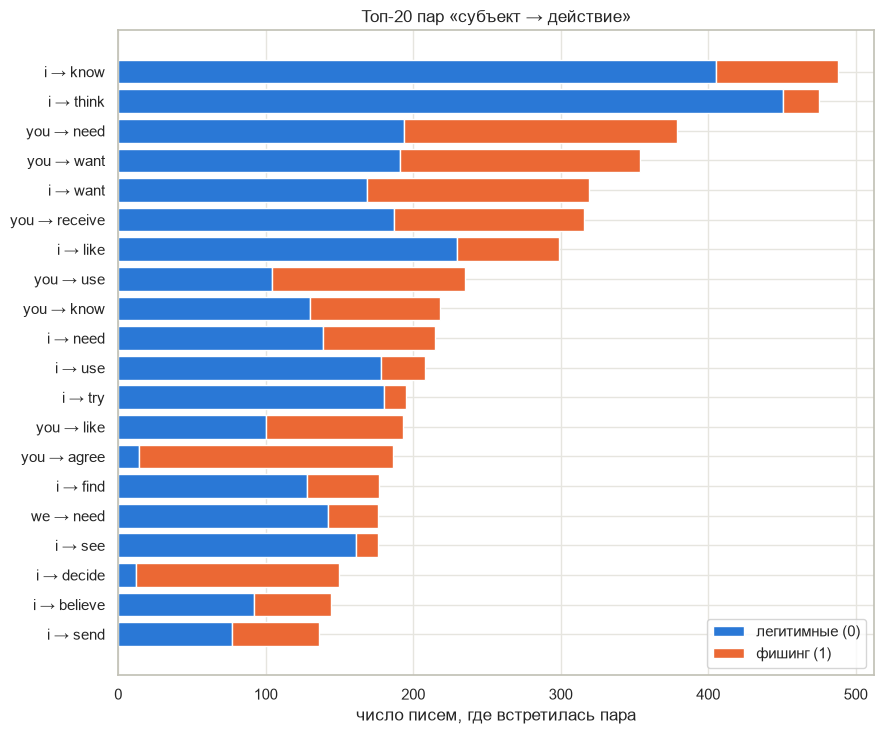

,писем,легит,фишинг,доля фишинга
pair,,,,
i → know,488,405,83,17%
i → think,475,451,24,5%
you → need,379,194,185,49%
you → want,354,191,163,46%
i → want,319,169,150,47%
you → receive,316,187,129,41%
i → like,299,230,69,23%
you → use,235,104,131,56%
you → know,218,130,88,40%


In [20]:
LIGHT_VERBS = {"be", "have", "do", "get", "go", "make", "let", "say", "can", "will", "would", "could", "should", "may"}
NONREF = {"it", "this", "that", "which", "who", "what", "there", "these", "those", "something", "anything", "all", "one",
          "here", "whom", "whatever", "nothing", "everything"}
base_verb = pairs["verb"].str.replace("not ", "").str.replace(" (pass)", "", regex=False)
pairs_f = pairs[~base_verb.isin(LIGHT_VERBS) & ~pairs["subj"].isin(NONREF)]

top = (pairs_f.drop_duplicates(["doc", "pair"]).groupby("pair")
       .agg(писем=("doc", "size"), фишинг=("label", "sum")))
top["легит"] = top["писем"] - top["фишинг"]
top["доля фишинга"] = top["фишинг"] / top["писем"]
top = top.sort_values("писем", ascending=False).head(20)[["писем", "легит", "фишинг", "доля фишинга"]]

t = top.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(t.index, t["легит"], color=CLASS_COLORS[0], label=CLASS_NAMES[0])
ax.barh(t.index, t["фишинг"], left=t["легит"], color=CLASS_COLORS[1], label=CLASS_NAMES[1])
ax.set_xlabel("число писем, где встретилась пара")
ax.set_title("Топ-20 пар «субъект → действие»")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "pairs_top20.png", dpi=120)
plt.show()
top.style.format({"доля фишинга": "{:.0%}"})

**Насколько пары отражают суть и тональность писем.**

* **Топ состоит из пар с личными местоимениями.** Даже после фильтрации конкретные существительные-подлежащие в топ-20 не попадают: в письмах действуют «я» и «вы». Но **доля фишинга** у пар разная, и она хорошо отражает характер классов.
* **Легитимная переписка — это эпистемическое первое лицо:** `i → think` (95% писем — легитимные), `i → know` (83%), `i → try` (92%), `i → see` (91%), `i → use` (86%), `we → need` (81%). Пишущий рассуждает, сомневается, делится опытом. Тон спокойный, деловой, технический.
* **Самые «фишинговые» пары:**
  * `you → agree` (92% фишинга) — подписочные и юридические футеры рассылок («by subscribing you agree…»). Субъект — получатель, ему навязывают согласие;
  * `i → decide` (92%) — зачин нигерийских писем («I decided to contact you…»). Отправитель-персонаж легенды объявляет о решении, которое касается получателя.
* **Пары `you → need / want / use / like / receive`** делятся между классами примерно поровну (41–56%). В фишинге это навязывание потребности (`you need`, `you want`), в легитимных письмах — обычная инструкция или ответ на вопрос. Пара без объекта эту разницу не передаёт.
* **Ограничения:**
  1. Пара «субъект + действие» передаёт **роли** (кто действует), но плохо передаёт **тональность**. Оценка в фишинге выражена прилагательными (`free`, `low`, `late`) и объектами действия (`verify account`, `claim fund`), а их в паре нет.
  2. **Местоимения-подлежащие** содержательно пусты. Подстановка антецедента из п. 6 превратила бы `he → deposit` в `father → deposit`.
  3. **Шаблонные рассылки** дают десятки одинаковых писем, поэтому пары считаются по документам. Без дедупликации почти одинаковых писем это решает проблему лишь частично.

## 6. Разрешение анафоры (rule-based)

**Задача:** для местоимений 3-го лица (`he/him/his`, `she/her`, `it/its`, `they/them/their` и указательного `this` в роли существительного) найти существительное-антецедент в предшествующем контексте и подставить его вместо местоимения.

**Алгоритм** (упрощённый вариант подходов Хоббса и Лаппина–Лиса, только на признаках из spaCy):

1. **Отбор местоимений.** `this` берём, только если он сам стоит в позиции существительного (`nsubj`, `dobj`, `pobj`), а не определяет его (`this account`). **Плеонастическое `it`** пропускаем, потому что оно ни на что не ссылается: `It is important that…`, `it seems that…`. Признаки: связь `expl` или подлежащее при `be/seem/appear/…` с придаточным `ccomp/xcomp/csubj` справа.
2. **Кандидаты:** вершины именных групп (NOUN/PROPN, не `compound`) в текущем предложении левее местоимения и в двух предыдущих предложениях.
3. **Морфологические фильтры:**
   * **число:** `Number=Sing/Plur` из `token.morph` у кандидата должно совпадать с числом местоимения. У PROPN без признака числа считаем Sing;
   * **род.** В английском у существительных нет грамматического рода, поэтому «род» кандидата восстанавливаем так: словарь имён NLTK (`names`: мужские / женские), NER-метка `PERSON`, лексикон лиц (`manager`, `customer`, `father`, `wife`…). `he/she` требуют лицо подходящего пола (или лицо без известного пола), `it/this` требуют не-лицо, `they` подходит обоим.
4. **Синтаксические ограничения:**
   * **принцип B** теории связывания: дополнение не может быть кореферентно подлежащему своей же клаузы (`John saw him` ≠ `John saw John`);
   * местоимение внутри относительного придаточного не ссылается на существительное, к которому это придаточное относится (`the fury it arouses`).
5. **Ранжирование по синтаксическому расстоянию.** Внутри предложения это длина пути между токенами в дереве зависимостей. Между предложениями считаем, что корни соседних предложений соединены ребром: путь = глубина местоимения + число границ предложений + глубина кандидата. Из расстояния вычитаем бонус за синтаксическую роль кандидата: подлежащее −2, прямое дополнение −1. Это предпочтение «центра внимания» дискурса, как в теории центрирования. При равенстве берём ближайшего слева.
6. **Подстановка.** Вместо местоимения ставим именную группу антецедента: вершину и её левые зависимые `det/amod/compound/poss/nummod`. Неопределённый артикль меняем на определённый (`a bank → the bank`). Для притяжательных форм добавляем `'s` (или `'` после `s`).

In [21]:
PRONOUNS = {  # форма -> (число, род, падеж)
    "he": ("Sing", "Masc", "nom"), "him": ("Sing", "Masc", "obj"), "his": ("Sing", "Masc", "poss"),
    "she": ("Sing", "Fem", "nom"), "her": ("Sing", "Fem", "obj"),
    "it": ("Sing", "Neut", "nom"), "its": ("Sing", "Neut", "poss"),
    "they": ("Plur", None, "nom"), "them": ("Plur", None, "obj"), "their": ("Plur", None, "poss"),
    "this": ("Sing", "Neut", "nom"),
}
MALE_NOUNS = {"man", "men", "mr", "sir", "father", "dad", "son", "brother", "husband", "boy", "gentleman", "king",
              "mister", "uncle", "chairman", "guy", "boyfriend", "prince"}
FEMALE_NOUNS = {"woman", "women", "mrs", "ms", "miss", "madam", "mother", "mom", "daughter", "sister", "wife", "girl",
                "lady", "queen", "aunt", "girlfriend", "widow", "princess"}
PERSON_NOUNS = MALE_NOUNS | FEMALE_NOUNS | {
    "person", "people", "customer", "client", "user", "member", "manager", "director", "officer", "friend", "employee",
    "colleague", "partner", "buyer", "seller", "recipient", "sender", "owner", "holder", "beneficiary", "banker",
    "lawyer", "attorney", "doctor", "student", "staff", "administrator", "admin", "agent", "victim", "investor",
    "author", "engineer", "analyst", "child", "children", "kid", "parent", "winner", "boss", "candidate", "applicant",
    "reader", "subscriber", "president", "minister", "developer", "team", "family", "relative"}
COLLECTIVE = {"team", "staff", "family", "people", "police", "management"}
MAX_SENT_BACK = 2
ROLE_BONUS = {"nsubj": 2, "nsubjpass": 2, "dobj": 1}


def noun_number(t):
    n = t.morph.get("Number")
    if n:
        return n[0]
    return "Sing" if t.pos_ == "PROPN" else None


def noun_gender(t):
    """'Род' существительного: Masc / Fem / Person (лицо, пол неизвестен) / Neut."""
    l = t.lower_
    is_name = t.pos_ == "PROPN" or t.ent_type_ == "PERSON"
    if l in MALE_NOUNS or (is_name and l in MALE_NAMES and l not in FEMALE_NAMES):
        return "Masc"
    if l in FEMALE_NOUNS or (is_name and l in FEMALE_NAMES and l not in MALE_NAMES):
        return "Fem"
    if t.ent_type_ == "PERSON" or l in PERSON_NOUNS or (is_name and l in ALL_NAMES):
        return "Person"
    return "Neut"


def gender_ok(pron_gender, cand_gender):
    if pron_gender is None:             # they/them/their: и лица, и предметы
        return True
    if pron_gender == "Neut":           # it/its/this
        return cand_gender == "Neut"
    return cand_gender in (pron_gender, "Person")


def is_target(t):
    l = t.lower_
    if l not in PRONOUNS:
        return False
    if l == "this":
        return t.pos_ == "PRON" and t.dep_ in ("nsubj", "nsubjpass", "dobj", "pobj")
    return t.pos_ in ("PRON", "DET") and t.tag_ in ("PRP", "PRP$")


def is_pleonastic(p):
    if p.lower_ != "it":
        return False
    if p.dep_ == "expl":
        return True
    h = p.head
    return (p.dep_ in ("nsubj", "nsubjpass")
            and h.lemma_ in ("be", "seem", "appear", "look", "happen", "take", "make", "matter")
            and any(c.dep_ in ("ccomp", "xcomp", "csubj") and c.i > h.i for c in h.children)) \
        or h.lemma_ in ("rain", "snow")


def tree_distance(a, b):
    pa, pb = [a, *a.ancestors], [b, *b.ancestors]
    ib = {t.i: k for k, t in enumerate(pb)}
    for k, t in enumerate(pa):
        if t.i in ib:
            return k + ib[t.i]
    return len(pa) + len(pb)


def depth(t):
    return sum(1 for _ in t.ancestors)


def syntactic_distance(p, c, sent_index):
    if sent_index[p.i] == sent_index[c.i]:
        return tree_distance(p, c)
    return depth(p) + (sent_index[p.i] - sent_index[c.i]) + depth(c)


def candidates(p, sents, sent_index):
    num, gen, _ = PRONOUNS[p.lower_]
    si = sent_index[p.i]
    start = sents[max(0, si - MAX_SENT_BACK)].start
    out = []
    for c in p.doc[start:p.i]:
        if c.pos_ not in ("NOUN", "PROPN") or c.text in PLACEHOLDERS or not c.is_alpha or c.dep_ in ("compound", "poss"):
            continue
        if c.head.i == p.i or p.head.i == c.i:
            continue
        if any(a.dep_ == "relcl" and a.head.i == c.i for a in p.ancestors):   # "the fury it arouses"
            continue
        if p.dep_ in ("dobj", "pobj", "dative") and c.dep_ in SUBJ_DEPS and c.head.i == p.head.i:  # принцип B
            continue
        cn, cg = noun_number(c), noun_gender(c)
        if cn and cn != num and not (num == "Plur" and c.lower_ in COLLECTIVE):
            continue
        if not gender_ok(gen, cg):
            continue
        d = syntactic_distance(p, c, sent_index)
        out.append((d - ROLE_BONUS.get(c.dep_, 0), -c.i, c, d))
    return sorted(out, key=lambda x: (x[0], x[1]))


NP_DEPS = {"det", "amod", "compound", "nummod", "poss", "nmod", "case"}


def np_text(c):
    keep, j = {c.i}, c.i - 1
    while j >= c.sent.start and c.doc[j].dep_ in NP_DEPS and c.doc[j].head.i in keep | set(range(j + 1, c.i)):
        keep.add(j)
        j -= 1
    toks = [c.doc[k] for k in sorted(keep)]
    words = [t.text_with_ws if k < len(toks) - 1 else t.text for k, t in enumerate(toks)]
    first = toks[0]
    if first.lower_ in ("a", "an"):
        words[0] = "the "
    elif first.i == first.sent.start and first.pos_ != "PROPN" and not first.is_upper:
        words[0] = words[0][0].lower() + words[0][1:]
    return "".join(words)


def replacement(p, c):
    t = np_text(c)
    if PRONOUNS[p.lower_][2] == "poss" or p.tag_ == "PRP$":     # her card -> Mary's card
        t += "'" if t.endswith("s") else "'s"
    if p.i == p.sent.start or p.is_title:
        t = t[0].upper() + t[1:]
    return t


def resolve_doc(doc):
    """Возвращает список (местоимение, антецедент, расстояние) для всех разрешённых местоимений документа."""
    sents = list(doc.sents)
    sent_index = {t.i: k for k, s in enumerate(sents) for t in s}
    res, skipped = [], Counter()
    for p in doc:
        if not is_target(p):
            continue
        if is_pleonastic(p):
            skipped["плеонастическое it"] += 1
            continue
        cands = candidates(p, sents, sent_index)
        if not cands:
            skipped["нет кандидата"] += 1
            continue
        res.append((p, cands[0][2], cands[0][3]))
    return res, skipped


def rewrite(span, links):
    """Текст span, где местоимения заменены на антецеденты: links = {i местоимения: (антецедент, местоимение)}."""
    return "".join((replacement(links[t.i][1], links[t.i][0]) if t.i in links else t.text) + t.whitespace_
                   for t in span).strip()

Применяем к подвыборке:

In [22]:
resolved, skip_stats = [], Counter()
for di, d in enumerate(docs):
    res, sk = resolve_doc(d)
    skip_stats += sk
    resolved += [(di, p, c, dist) for p, c, dist in res]
n_targets = len(resolved) + sum(skip_stats.values())
print(f"Местоимений-целей: {n_targets:,}; разрешено: {len(resolved):,}; пропущено: {dict(skip_stats)}")

Местоимений-целей: 19,144; разрешено: 15,925; пропущено: {'нет кандидата': 2393, 'плеонастическое it': 826}


**Сравнение исходных и изменённых предложений** (15 случайных примеров из корпуса). Показываем окно контекста: антецедент выделен `**…**`, местоимение — `[[…]]`. Далёкие части склеены через ` … `.

In [23]:
def show_case(di, p, c, w=8):
    d = docs[di]
    if p.i - c.i <= 3 * w:
        spans = [d[max(c.sent.start, c.i - w): min(p.sent.end, p.i + w + 1)]]
    else:
        spans = [d[max(c.sent.start, c.i - w): c.i + w + 1], d[max(c.i + w + 1, p.i - w): min(p.sent.end, p.i + w + 1)]]
    mark = lambda t: f"**{t.text}**" if t.i == c.i else f"[[{t.text}]]" if t.i == p.i else t.text
    orig = " … ".join("".join(mark(t) + t.whitespace_ for t in s).strip() for s in spans)
    new = " … ".join(rewrite(s, {p.i: (c, p)}) for s in spans)
    return {"источник": sample["source"][di], "label": sample["label"][di], "местоимение": p.text,
            "антецедент": np_text(c), "исходный текст": orig.replace("\n", " "), "после замены": new.replace("\n", " ")}


rnd = random.Random(SEED)
cases = pd.DataFrame([show_case(di, p, c) for di, p, c, _ in rnd.sample(resolved, 15)])
cases.index = range(1, len(cases) + 1)
cases

,источник,label,местоимение,антецедент,исходный текст,после замены
1,Enron,0,this,tonight,i am flying to houston **tonight** and wondered if it would fit one or both of your schedules to get together [[this]] coming tuesday sometime for 1 / 2 hour,i am flying to houston tonight and wondered if it would fit one or both of your schedules to get together tonight coming tuesday sometime for 1 / 2 hour
2,CEAS_08,0,they,developers,"sounds like they are | ""nations of **developers**"" which [[they]] might become","sounds like they are | ""nations of developers"" which developers might become"
3,CEAS_08,0,this,sense,That doesn't make **sense**. Maybe I am misunderstanding [[this]].,That doesn't make sense. Maybe I am misunderstanding sense.
4,Enron,1,its,today,**today** [[its]] only an amazing $ 3. 00 shipped,today today's only an amazing $ 3. 00 shipped
5,CEAS_08,0,they,autoyast users,Are autoyast **users** finding [[they]] cannot make persistent changes to some system,Are autoyast users finding autoyast users cannot make persistent changes to some system
6,Nigerian_Fraud,1,him,our client,"Before the U.S and Iraqi war our **client** Major Fadi Basem who was with the Iraqi … . Upon maturity several notice was sent to [[him]], even during the wa...","Before the U.S and Iraqi war our client Major Fadi Basem who was with the Iraqi … . Upon maturity several notice was sent to our client, even during the war..."
7,Nigerian_Fraud,1,he,President Aristed,"members of the United Nations, (President **Aristed**) decided,and left the seat of … these sad happenings, there was this deposit [[he]] made with a Securi...","members of the United Nations, (President Aristed) decided,and left the seat of … these sad happenings, there was this deposit President Aristed made with a..."
8,Enron,0,them,the few hours,"arco is going down for a few **hours** in the morning on thursday, 8 / … 2 - 9, in spl 5 for [[them]].","arco is going down for a few hours in the morning on thursday, 8 / … 2 - 9, in spl 5 for the few hours."
9,Nigerian_Fraud,1,THIS,YOUR ASSISTANCE,FROM HAVING FOREIGN ACCOUNT HENCE WE NEED YOUR **ASSISTANCE** MOST URGENTLY. [[THIS]] IS ALSO A HIGHLY CONFIDENTIAL MATTER,FROM HAVING FOREIGN ACCOUNT HENCE WE NEED YOUR ASSISTANCE MOST URGENTLY. YOUR ASSISTANCE IS ALSO A HIGHLY CONFIDENTIAL MATTER
10,Enron,0,it,seasonal differential,edison's seasonal **differential** is intended to lessen the costs imposed upon [[it]] by its prominent summer peak.,edison's seasonal differential is intended to lessen the costs imposed upon seasonal differential by its prominent summer peak.


**Сравнение исходных и изменённых предложений.**

* Из 19 144 местоимений-целей разрешено 15 925. Плеонастических `it` найдено и пропущено 826, без подходящего кандидата осталось 2 393 (в основном `he/she` без лица в контексте и `they` в начале письма).
* **Верные замены** (5 из 15 примеров): №2 `which they might become` → `which developers might become`, №5 `autoyast users finding they cannot` → `… finding autoyast users cannot`, №6 `sent to him` → `sent to our client`, №7 `deposit he made` → `deposit President Aristed made`, №12 `its requirements` → `the PCI standard's requirements`. Работают фильтр числа (`they` → множественное `users`), фильтр рода (`he/him` → лицо) и притяжательная форма. После замены предложение понятно без контекста. Это особенно полезно для нигерийских писем, где местоимения отсылают к персонажам легенды.
* **Неверные замены и их причины:**
  * **`this`/`it` указывает на ситуацию, а не на предмет** (№3 `misunderstanding this` → `misunderstanding sense`, №9, №11, №13, №14 `time to do it`). Местоимение заменяет целое высказывание или действие, и выбор любого существительного ломает смысл;
  * **ошибки разметки:** №1 `this coming tuesday` — `this` здесь определитель, но тэггер пометил его PRON; №4 `its only $3` — опечатка вместо `it's`;
  * **ближайший кандидат грамматически подходит, но по смыслу нужен другой:** №10 `costs imposed upon it` = edison, а не differential; №8 `them` = станции, а не hours; №15 `assist you with it` = здоровье, а не Summer. Синтаксическое расстояние и роль подлежащего не учитывают смысл.
* **Как улучшить:** перед поиском антецедента нужен фильтр «референтное / нереферентное местоимение». `this` стоит разрешать только в конструкции `this is + NOUN`, а для выбора между грамматически допустимыми кандидатами нужна семантическая совместимость с глаголом (кто может `deposit`, что можно `verify`).

## Итоги

1. **Данные.** Для морфологии и синтаксиса нужен текст с регистром и пунктуацией, поэтому вместо предобработанного `phishing_email.csv` взяты сырые письма. Очистка щадящая: только почтовые артефакты, плейсхолдеры URL/EMAIL и склейка жёстких переносов строк.
2. **POS-профиль фишинга:** больше прилагательных (×1,5), местоимений и наречий. Меньше пунктуации, чисел, вспомогательных глаголов и междометий. Легитимные письма — рассуждения и техника, фишинг — оценки и обращение к получателю.
3. **Ошибки тэггера** (5 механизмов): капс → PROPN; нижний регистр → имена становятся NOUN; обфускация; этикетные формулы → PROPN; технический мусор.
4. **Деревья зависимостей** правильно передают связку, пассив, относительные и сочинённые конструкции. Ломаются на дефисах, склеенных темах писем, цитатах и разделительных вопросах.
5. **Пары «субъект → действие»** после фильтрации лёгких глаголов и подсчёта по документам разделяют классы по ролям. Первое лицо с глаголами мнения (`i → think`) — легитимная переписка. `you → agree` и `i → decide` — фишинг. Тональность пары передают слабо.
6. **Анафора на правилах** верно работает для лиц и конкретных предметов (5 из 15 разобранных примеров). Ошибается на `this`/`it`, которые указывают на ситуацию, и там, где нужен смысл, а не грамматика.